In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('/content/credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [4]:
df.shape

(32581, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [6]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [7]:
df['loan_status'].unique()
df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

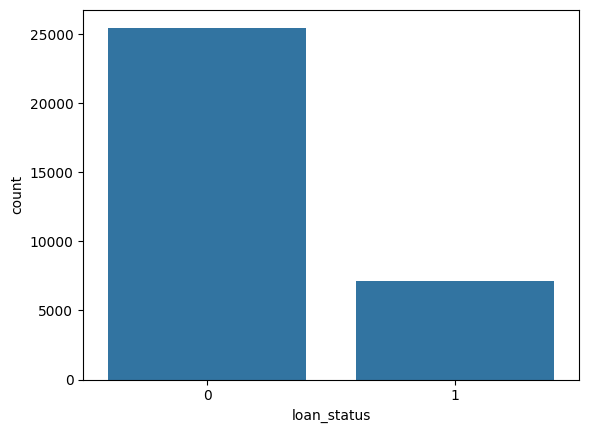

In [8]:
sns.countplot(x='loan_status',data = df)# class imbalance issue

In [9]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [10]:
num_cols = df.select_dtypes(include=np.number)
num_cols

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
0,22,59000,123.0,35000,16.02,1,0.59,3
1,21,9600,5.0,1000,11.14,0,0.10,2
2,25,9600,1.0,5500,12.87,1,0.57,3
3,23,65500,4.0,35000,15.23,1,0.53,2
4,24,54400,8.0,35000,14.27,1,0.55,4
...,...,...,...,...,...,...,...,...
32576,57,53000,1.0,5800,13.16,0,0.11,30
32577,54,120000,4.0,17625,7.49,0,0.15,19
32578,65,76000,3.0,35000,10.99,1,0.46,28
32579,56,150000,5.0,15000,11.48,0,0.10,26


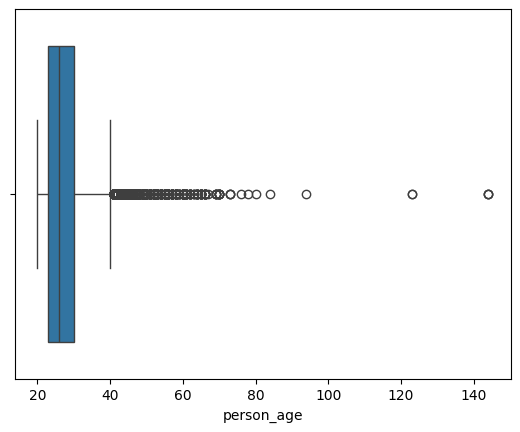

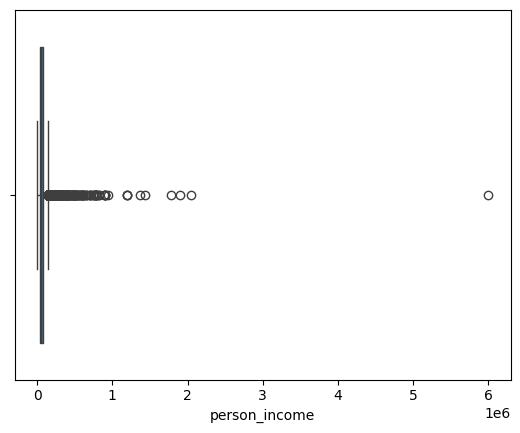

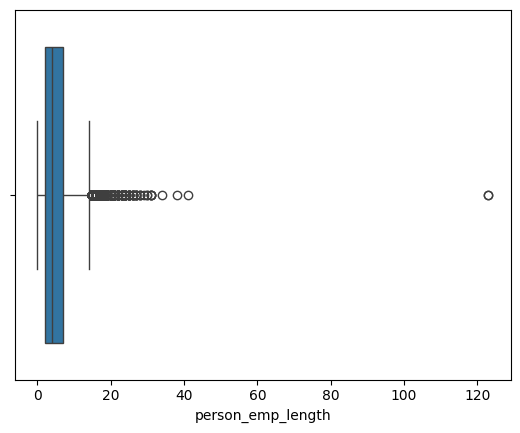

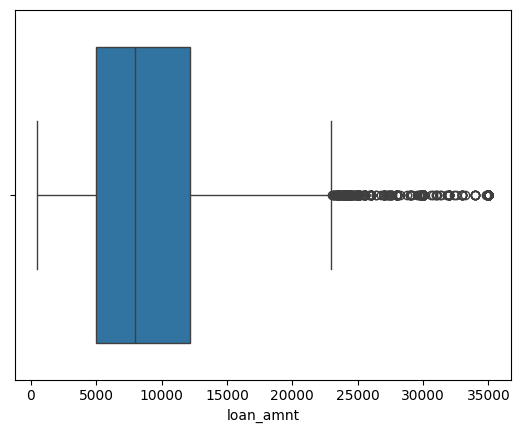

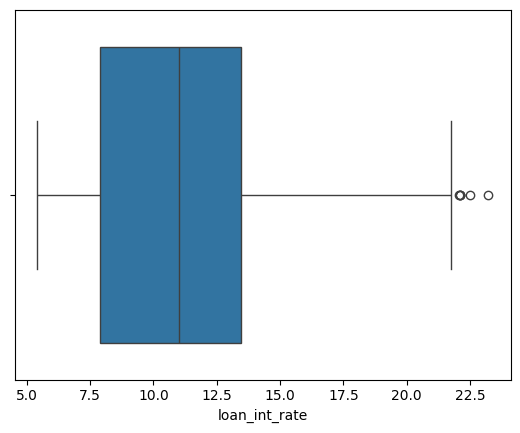

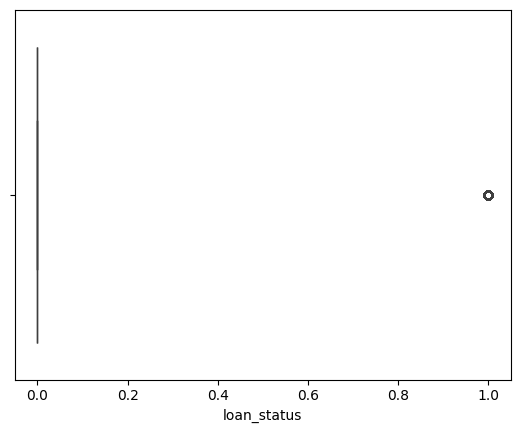

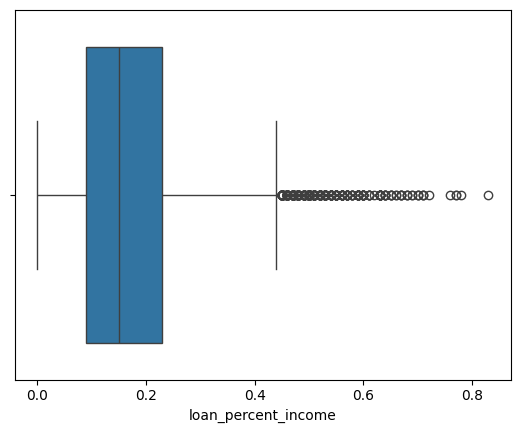

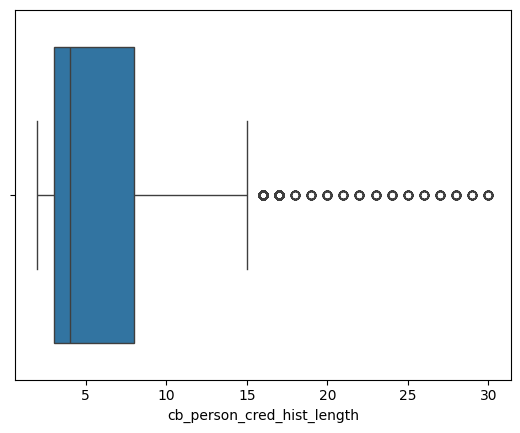

In [11]:
for i in num_cols:
  sns.boxplot(x=df[i])
  plt.show()

In [12]:
(df['person_age']>100).sum()

np.int64(5)

<Axes: >

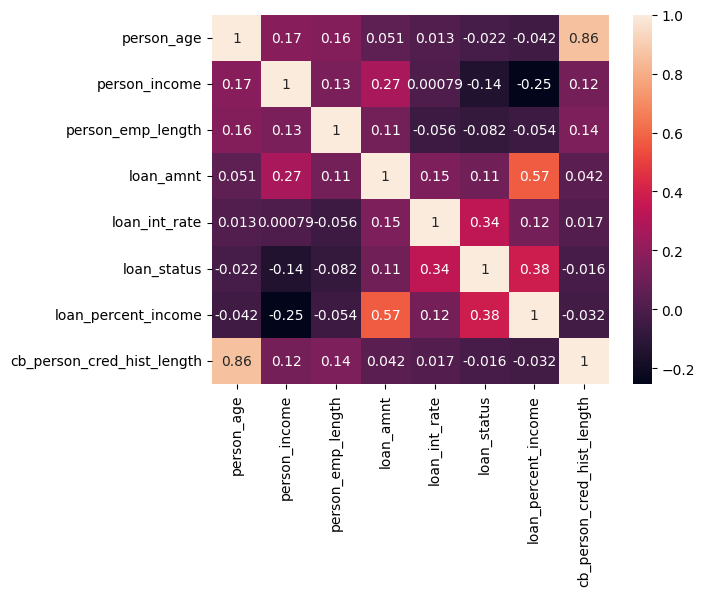

In [13]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [14]:
df_copy = df.copy()
print(f'original number of rows: {df_copy.shape[0]}')

df_copy.drop_duplicates(inplace=True)

print(f'number of rows after dropping duplicates: {df_copy.shape[0]}')



original number of rows: 32581
number of rows after dropping duplicates: 32416


In [15]:
df_copy = df_copy[df_copy['person_age']>=18]
df_copy = df_copy[df_copy['person_age']<=100]

df_copy = df_copy[df_copy["person_emp_length"]<= df_copy['person_age']]
df_copy = df_copy[df_copy["person_emp_length"]<= 60]

df_copy = df_copy[df_copy['loan_amnt']>=0]
df_copy = df_copy[df_copy['loan_int_rate']>=0]
df_copy









,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [16]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                     'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

In [17]:
from sklearn.metrics import classification_report
from sklearn.metrics import precision_recall_curve
def evaluate_model(model_name , model , X_test , y_test, threshold = None):# high threshold value for Spam filtering / Loan approval	Avoid false alarms (High Precision). False positives cause heavy friction.
  y_pred_prob = model.predict_proba(X_test)[:,1]                            #fraud detection / Disease screening	Catch as many positives as possible (High Recall). Missing a case is dangerous.	Lower threshold (e.g., 0.2 or 0.3)

  if threshold is not None:
    y_pred = (y_pred_prob > threshold).astype(int)
  else:
    y_pred = model.predict(X_test)

  from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
  #metrics
  accuracy = accuracy_score(y_test, y_pred)
  precision = precision_score(y_test, y_pred) #of the one i picked how many are predicted true , model says 1 then how many are actually 1
  recall = recall_score(y_test, y_pred)# out of everything there how many you were able to find , out of total 1 how many we found
  f1_score = f1_score(y_test, y_pred)# harominc mean of precision and recall
  roc_auc = roc_auc_score(y_test, y_pred_prob)
  print(f"Accuracy : {accuracy}")
  print(f"Precision : {precision}")
  print(f"Recall : {recall}")
  print(f"F1 : {f1_score}")
  print(f"ROC-AUC : {roc_auc}")
  print(f"Classification Report : \n{classification_report(y_test, y_pred)}")

  # confusion matrix
  cm = confusion_matrix(y_test, y_pred)
  class_report = classification_report(y_test, y_pred)

  # plot confusion matrix
  sns.heatmap(cm,annot = True , fmt = 'g')
  plt.xlabel('Predicted')
  plt.ylabel('Actual')
  plt.title(f'{model_name} Confusion Matrix')
  plt.show()

  #plot roc curve
  precisions, recalls , threshold = precision_recall_curve(y_test, y_pred_prob)
  plt.plot(recalls, precisions)
  plt.xlabel('Recall')
  plt.ylabel('Precision')
  plt.title(f'{model_name} Precision-Recall Curve')
  plt.show()


In [18]:
X = df_copy.drop('loan_status', axis=1)
y = df_copy['loan_status'] #1, 0


from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [19]:
# class weighs
y_train.value_counts()
neg , pos = np.bincount(y_train)
weight_factor = neg/pos

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

# 1. Logistic Regression Preprocessor
preprocessor_lr = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="mean")),
            ("scaler", StandardScaler())
        ]), numeric_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value='missing')),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols)
    ])

# 2. Logistic Regression Model Pipeline
model_lr = Pipeline([
    ("preprocessor", preprocessor_lr),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])


# 3. XGBoost Preprocessor (No scaling)
preprocessor_XG = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="mean")),
        ]), numeric_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value='missing')),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols)
    ])

In [21]:
# cross validation
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring ={'roc_auc':'roc_auc', 'accuracy':'accuracy', 'precision':'precision', 'recall':'recall', 'f1':'f1'}

# from sklearn.model_selection import cross_val_score

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from xgboost import XGBClassifier


lr_crosval_pipeline = Pipeline([
    ("preprocessor", preprocessor_lr),
    ("classifier", LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

xgb_crosval_pipeline = Pipeline([
    ("preprocessor", preprocessor_XG),
    ("classifier", XGBClassifier(booster='gbtree',n_estimator = 300 , max_depth = 5 ,learning_rate = 0.1,#as there is no class_wweigh in xgboost model we manually put it
        scale_pos_weight = weight_factor,
        random_state = 42,
        verbosity = 0,
        n_jobs= 1))
])


models = [
    ('LogisticRegression', lr_crosval_pipeline),
    ('XGBClassifier', xgb_crosval_pipeline)
]


for cv_name, pipe in models:
   scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
   print(cv_name)
   print(f"ROC-AUC : {scores['test_roc_auc'].mean()}")
   print(f"Accuracy : {scores['test_accuracy'].mean()}")
   print(f"Precision : {scores['test_precision'].mean()}")
   print(f"Recall : {scores['test_recall'].mean()}")
   print(f"F1 : {scores['test_f1'].mean()}")







LogisticRegression
ROC-AUC : 0.8723189618970608
Accuracy : 0.8125108614924017
Precision : 0.5482946003214749
Recall : 0.775959595959596
F1 : 0.6425345950302089
XGBClassifier
ROC-AUC : 0.9386779397235119
Accuracy : 0.9054662552960598
Precision : 0.7827449631584541
Recall : 0.7824242424242425
F1 : 0.782315486438731


In [23]:
pd.DataFrame(scores)

,fit_time,score_time,test_roc_auc,test_accuracy,test_precision,test_recall,test_f1
0,0.539927,0.096280,0.937620,0.896711,0.755162,0.775758,0.765321
1,0.477606,0.094621,0.940513,0.909410,0.803365,0.771717,0.787223
2,0.473290,0.093459,0.940900,0.908094,0.772684,0.817172,0.794305
3,0.468574,0.093907,0.930477,0.902830,0.786387,0.758586,0.772237
4,0.300323,0.057361,0.943880,0.910287,0.796126,0.788889,0.792491


In [24]:
baseline_model = lr_crosval_pipeline
baseline_model.fit(X_train, y_train)
y_pred_lr = baseline_model.predict(X_test)

In [25]:
xg_model = xgb_crosval_pipeline
xg_model.fit(X_train,y_train)
y_pred_xg = xg_model.predict(X_test)

Accuracy : 0.81751184418319
Precision : 0.5569693464430306
Recall : 0.778496362166532
F1 : 0.6493594066082266
ROC-AUC : 0.8729735008317792
Classification Report : 
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4462
           1       0.56      0.78      0.65      1237

    accuracy                           0.82      5699
   macro avg       0.74      0.80      0.76      5699
weighted avg       0.85      0.82      0.83      5699



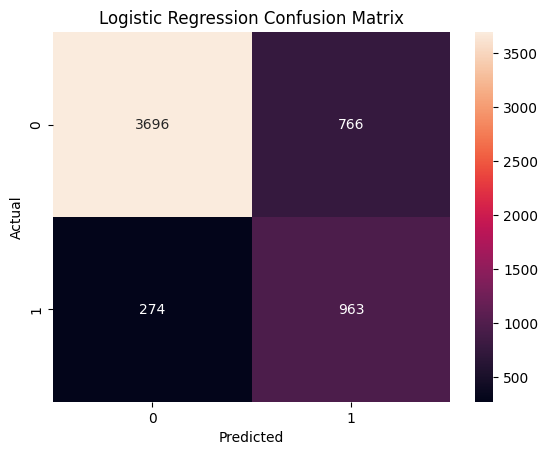

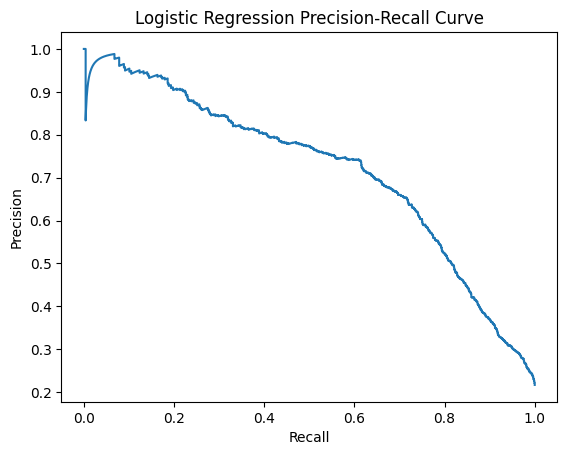

In [26]:
evaluate_model('Logistic Regression', baseline_model, X_test, y_test)

Accuracy : 0.9108615546587121
Precision : 0.7899761336515513
Recall : 0.8027485852869847
F1 : 0.7963111467522053
ROC-AUC : 0.9445547907108878
Classification Report : 
              precision    recall  f1-score   support

           0       0.95      0.94      0.94      4462
           1       0.79      0.80      0.80      1237

    accuracy                           0.91      5699
   macro avg       0.87      0.87      0.87      5699
weighted avg       0.91      0.91      0.91      5699



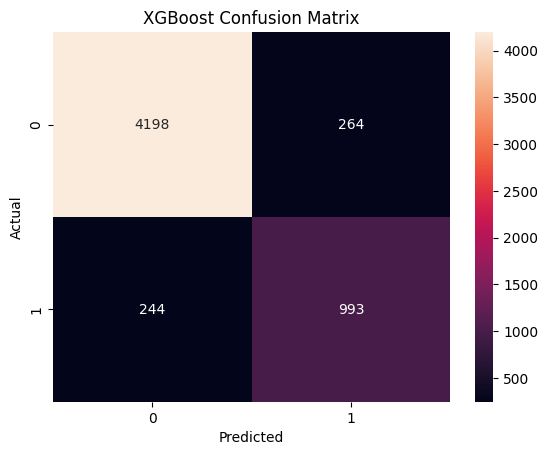

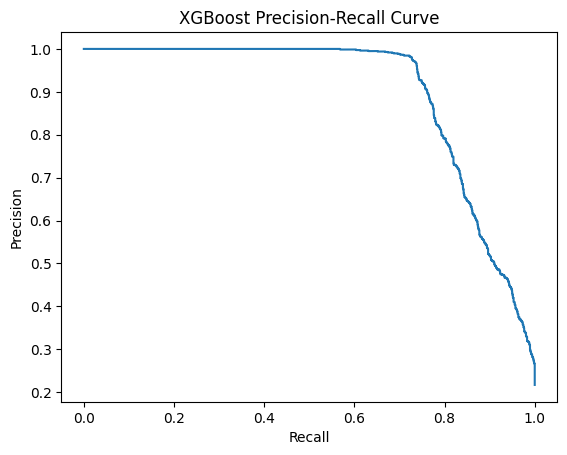

In [27]:
evaluate_model('XGBoost', xg_model, X_test, y_test)

In [28]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint
param_grid = {
    'classifier__n_estimators': [100, 200],              # Cap estimators to avoid runaway training
    'classifier__max_depth': [3, 5, 7],                  # Keep trees shallow to avoid exponential splits
    'classifier__learning_rate': [0.03, 0.1],
    'classifier__subsample': [0.8, 1.0],#random rows sampling
    'classifier__colsample_bytree': [0.8, 1.0],#random column sampling
    'classifier__min_child_weight': [1, 3, 5],# how easily we can split , after every split we are getting an improvment or not
    'classifier__gamma':uniform(0,5) # low gamma means more leaves and more complex tree therfore risk of high overfitting and vice versa
}
#     'classifier__n_estimators': randint(150,600),
#     'classifier__max_depth':  randint(3,7),
#     "classifier__learning_rate": uniform(0.01,0.5),
#     'classifier__subsample': uniform(0.6,0.4),#random rows sampling
#     'classifier__colsample_bytree': uniform(0.6,0.4),#random column sampling
#     'classifier__min_child_weight':randint(0,10), # how easily we can split , after every split we are getting an improvment or not
#     'classifier__gamma':uniform(0,5) # low gamma means more leaves and more complex tree therfore risk of high overfitting and vice versa

# }




In [29]:
random_search = RandomizedSearchCV(
    estimator = xgb_crosval_pipeline,
    param_distributions=param_grid,
    n_iter=10,
    scoring='average_precision',
    cv=cv,
    verbose=1,
    n_jobs=1
)


In [30]:
random_search.fit(X_train, y_train)
best_model = random_search.best_estimator_

Fitting 5 folds for each of 10 candidates, totalling 50 fits


In [31]:
import warnings

# Suppress XGBoost and UserWarnings from flooding the notebook cell
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', module='xgboost')
print(xgb_crosval_pipeline.named_steps.keys())

dict_keys(['preprocessor', 'classifier'])


In [32]:
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer())]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length']),
                                                                              ('cat',
                                                                               Pipeli...
                   param_distributions={'classifier__colsample_bytree': [0.8,
                                                                         1.0],
                                        'classifier__gamma': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7fab5385fe00>,
                                        'classifier__learning_rate': [0.03,
                                                                      0.1],
                                        'classifier__max_depth': [3, 5, 7],
                                        'classifier__min_child_weight': [1, 3,
                                                                         5],
                                        'classifier__n_estimators': [100, 200],
                                        'classifier__subsample': [0.8, 1.0]},
                   scoring='average_precision', verbose=1)

In [33]:
random_search.best_params_
random_search.best_score_


np.float64(0.8908427806632216)

Accuracy : 0.9173539217406562
Precision : 0.8207705192629816
Recall : 0.7922392886014551
F1 : 0.8062525709584533
ROC-AUC : 0.945780537128947
Classification Report : 
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4462
           1       0.82      0.79      0.81      1237

    accuracy                           0.92      5699
   macro avg       0.88      0.87      0.88      5699
weighted avg       0.92      0.92      0.92      5699



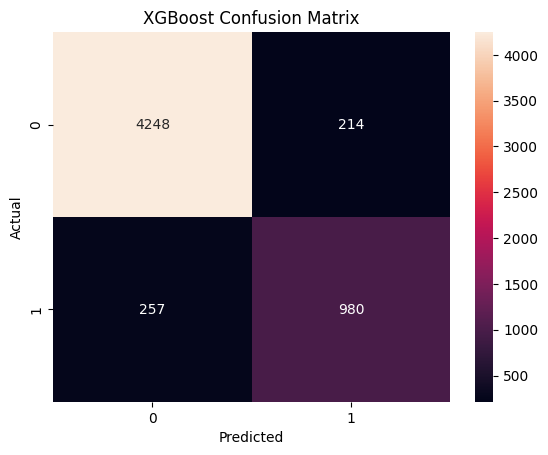

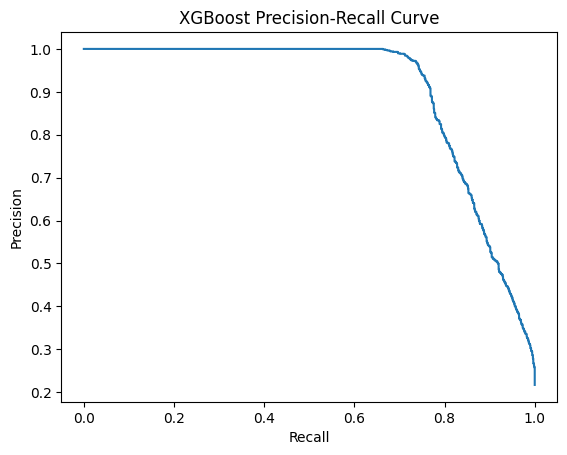

In [34]:
#now evaluate tuned model
evaluate_model("XGBoost", random_search, X_test, y_test)

In [35]:
# model gives probabality and the threshold value finally decides the what value to make decision


In [38]:
# calibration

from sklearn.calibration import CalibratedClassifierCV , calibration_curve
calibrated_model = CalibratedClassifierCV(
    best_model,
    method = 'sigmoid',
    cv = 5

)
calibrated_model.fit(X_train, y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer())]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(fill_value='miss...
                                                                gamma=np.float64(4.111543645311936),
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=0.1,
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=7,
                                                                max_leaves=None,
                                                                min_child_weight=5,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimator=300,
                                                                n_estimators=100,
                                                                n_jobs=1, ...))]))

In [39]:
uncalibrated = xg_model.predict_proba(X_test)[:,1]
calibrated = calibrated_model.predict_proba(X_test)[:,1]
calibrated

array([0.95161332, 0.9602935 , 0.00999667, ..., 0.08336941, 0.01024172,
       0.95676166])

In [41]:
from sklearn.metrics import precision_recall_curve

prob = xg_model.predict_proba(X_test)
pd.DataFrame(prob)
precisions, recalls, thresholds = precision_recall_curve(y_test, calibrated)

f1 = 2 * (precisions*recalls) / (precisions + recalls + 1e-9)
best = np.argmax(f1[:-1])
best_threshold = thresholds[best] # where f1 score are max in our case
best_threshold

np.float64(0.6064269556636146)

Accuracy : 0.929110370240393
Precision : 0.8940397350993378
Recall : 0.7639450282942603
F1 : 0.8238884045335658
ROC-AUC : 0.9445547907108878
Classification Report : 
              precision    recall  f1-score   support

           0       0.94      0.97      0.96      4462
           1       0.89      0.76      0.82      1237

    accuracy                           0.93      5699
   macro avg       0.92      0.87      0.89      5699
weighted avg       0.93      0.93      0.93      5699



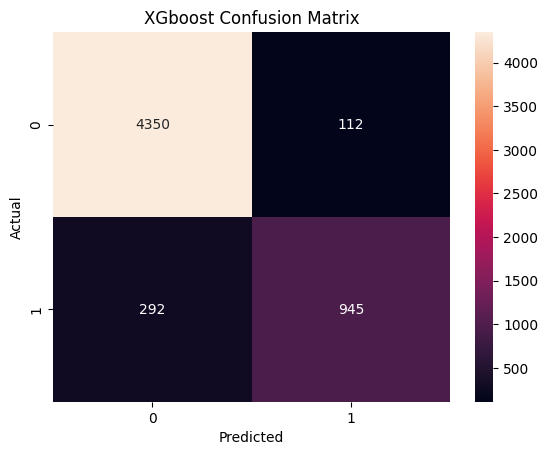

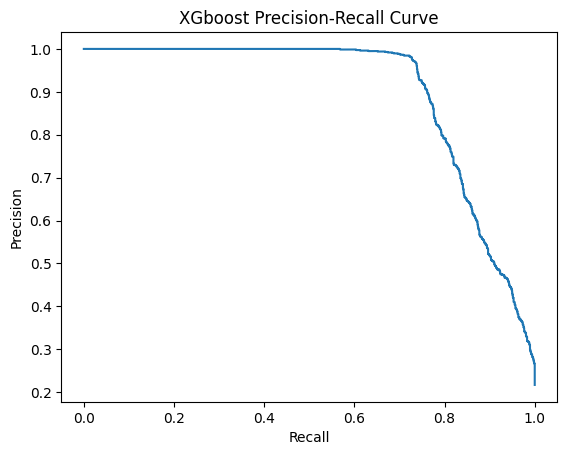

In [42]:
evaluate_model('XGboost',xg_model,X_test,y_test,best_threshold)

In [43]:
actual_uncal , predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins=10)
actual_cal , predicted_cal = calibration_curve(y_test, calibrated, n_bins=10)

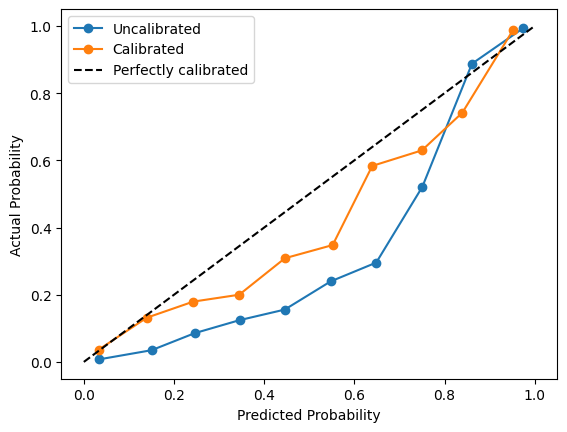

In [44]:
plt.plot(
    predicted_uncal,
    actual_uncal,
    'o-',
    label = 'Uncalibrated'
)

plt.plot(
    predicted_cal,
    actual_cal,
    'o-',
    label = 'Calibrated'


)
plt.plot([0,1],[0,1],'k--',label = 'Perfectly calibrated')
plt.xlabel('Predicted Probability')
plt.ylabel('Actual Probability')
plt.legend()


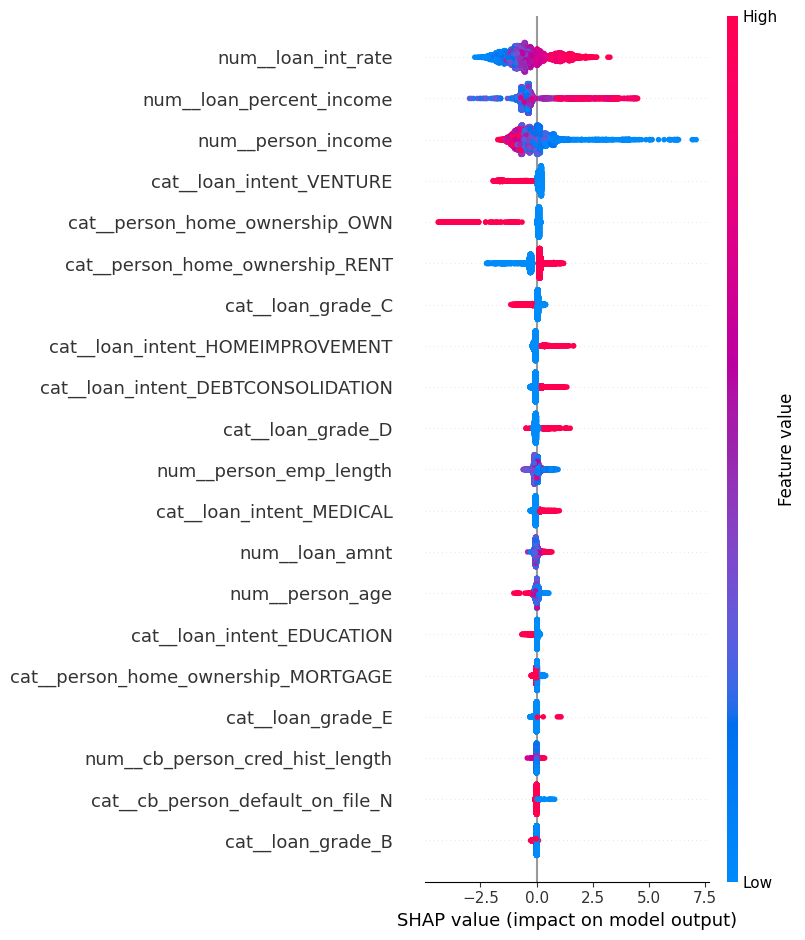

In [45]:
# shap interpretation , it shows which feature matters the most local and global analysis
import shap
xgb_classifier = xg_model.named_steps['classifier']
# explainer = shap.TreeExplainer(xgb_classifier)
# shap_values = explainer.shap_values(X_test)
# shap.summary_plot(shap_values,

X_test_transformed = xg_model.named_steps['preprocessor'].transform(X_test)
xg_model.named_steps['preprocessor'].get_feature_names_out()

X_test_df = pd.DataFrame(X_test_transformed , columns = xg_model.named_steps['preprocessor'].get_feature_names_out())

explainer = shap.TreeExplainer(xgb_classifier)
shap_values = explainer.shap_values(X_test_df)
shap.summary_plot(shap_values,X_test_df)



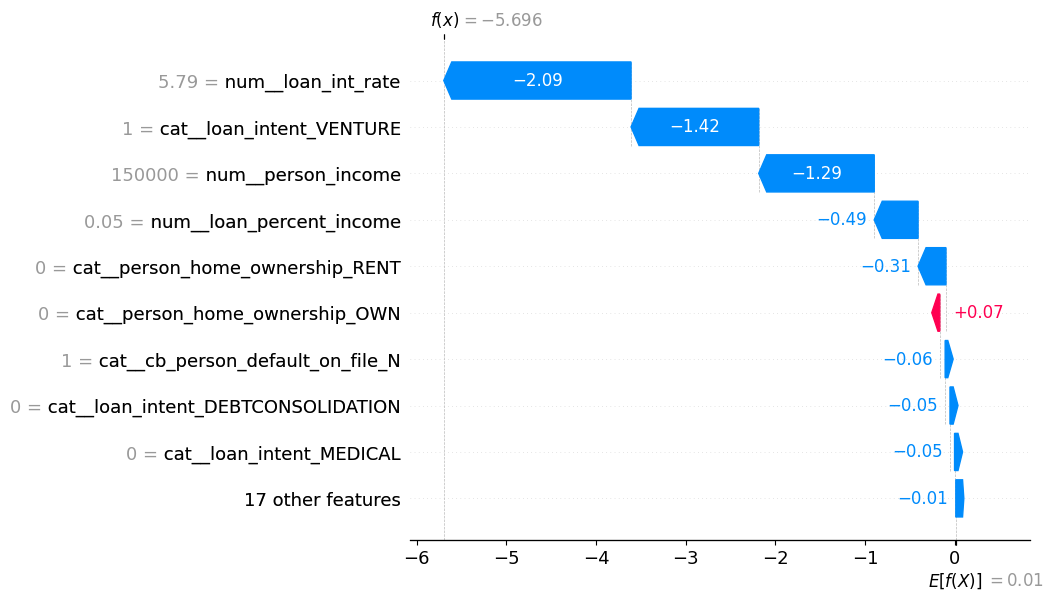

In [46]:
# local analysis of the shap
row_index = 5

shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = xg_model.named_steps['preprocessor'].get_feature_names_out()
    )
)

In [47]:
# analysing false positive and false negative
y_pred = random_search.predict(X_test)



In [48]:
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred
result_df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
13588,23,46000,RENT,2.0,EDUCATION,F,12800,19.41,0.28,Y,3,1,1
6107,24,16800,RENT,2.0,DEBTCONSOLIDATION,D,6000,14.84,0.36,Y,4,1,1
6052,24,120000,RENT,0.0,VENTURE,A,5775,6.17,0.05,N,2,0,0
7402,22,41838,RENT,0.0,MEDICAL,D,6600,16.89,0.16,N,3,1,1
21698,33,44000,MORTGAGE,2.0,EDUCATION,C,7000,12.99,0.16,Y,8,1,0


In [49]:
false_positives = result_df[(result_df['actual'] == 0) & (result_df['predicted'] == 1)]
false_neagtive = result_df[(result_df['actual'] == 1) & (result_df['predicted'] == 0)]
print(f'false positives : {len(false_positives)}')
print(f'false negatives : {len(false_neagtive)}')


false positives : 214
false negatives : 257


In [50]:
from sklearn.metrics import precision_recall_curve

prob = xg_model.predict_proba(X_test)
pd.DataFrame(prob)
precisions, recalls, thresholds = precision_recall_curve(y_test, calibrated)

f1 = 2 * (precisions*recalls) / (precisions + recalls + 1e-9)
best = np.argmax(f1[:-1])
best_threshold = thresholds[best] # where f1 score are max in our case
best_threshold

np.float64(0.6064269556636146)

In [51]:
import joblib
joblib.dump(calibrated_model , 'Credit_Risk_Assesment.pkl')


['Credit_Risk_Assesment.pkl']

In [52]:
joblib.dump(best_threshold,'Best_Threshold.pkl')

['Best_Threshold.pkl']